In [7]:
import numpy as np
import pandas as pd
import scipy as sp
import matplotlib.pyplot as plt
import pickle as pkl
import plumed
import matplotlib.ticker as ticker

#Silence unimportant warnings
import warnings
warnings.filterwarnings("ignore", message="cannot load PLUMED instance")
warnings.simplefilter("ignore", FutureWarning)
warnings.simplefilter("ignore", RuntimeWarning)

import sys
sys.path.append(".")
import B22_from_distances as b22

## Data preprocessing

In [8]:
ipath = "./"
systems = ["Man9"]
conditions = ["TIP3P", "TIP4PD", "TIP4PD--"]

data = {}
data['label'] = {}
data['path'] = {}
data['distance'] = {}
data['temperature'] = {}
data['is_restrained'] = {}
data['k_in_kJ_per_M_per_nm2'] = {}
data['k_in_kbT'] = {}

keys = {}

for s in systems:
    for c in conditions:
        keys[s] = conditions
        key_name = s + "/" + c
        data['label'][key_name] = key_name
        data['path'][key_name] = ipath + s + "/" + c
        df = plumed.read_as_pandas("{}/TOPO0/COLVAR.0".format(data['path'][key_name]))
        df = df.loc[:,["time","distance"]]
        df.to_csv("{}/distance.dat".format(data['path'][key_name]), sep = " ", header=False, index=False)
        data['distance'][key_name] = np.loadtxt("{}/distance.dat".format(data['path'][key_name]))
        data['distance'][key_name][:,0] /= 1e6 # time from ps to microseconds
        data['temperature'][key_name] = 300.
        data['is_restrained'][key_name] = True
        data['k_in_kJ_per_M_per_nm2'][key_name] = 1000.
        data['k_in_kbT'][key_name] = b22.get_k(data['k_in_kJ_per_M_per_nm2'][key_name], T=data['temperature'][key_name])
        
keys['all'] = [s + "/" + c for s in systems for c in conditions]

#Store if desired
with open("Man9/keys_Man9.pkl", "wb") as fp:
    pkl.dump(keys, fp)
with open("Man9/data_Man9.pkl", "wb") as fp:
    pkl.dump(data, fp)

#Load if desired
#with open("/perm/grothaus/B22/A2/keys_A2.pkl", "rb") as fp:
#    keys=pkl.load(fp)
#with open("/perm/grothaus/B22/A2/data_A2.pkl", "rb") as fp:
#    data=pkl.load(fp)

## B22 calculation - minimal example

Direct calculation of B22 with predefined R1 and R2 cutoffs

In [9]:
R1 = 5
R2 = 15
n_blocks = 5

for key in keys["all"]:
    print("Processing system: {}".format(key))
    distances = b22.apply_pbcs(data['distance'][key], R2)  # return distances and corresponding energies when distances are smaller than R2
    w = b22.get_weights(distances, data['k_in_kbT'][key])  # calculate weights from gamma distribution
    B22_blocks = b22.block_averaging(distances, w, R1, R2, n_blocks) #calculate B22 values for every block via block averaging for the distances
    B22_average, B22_std, B22_st_error = b22.get_blocked_std_fixed_M(B22_blocks, n_blocks) 
    B22_in_l_per_mol = B22_average * (1e-24 * (6.022e23))
    B22_st_error_in_l_per_mol = B22_st_error * (1e-24 * (6.022e23))
    print("B22 = {:.3f} +/- {:.3f} L/mol".format(B22_in_l_per_mol, B22_st_error_in_l_per_mol))
    print("--------------------------------------------------") 

Processing system: Man9/TIP3P
B22 = -597.463 +/- 406.614 L/mol
--------------------------------------------------
Processing system: Man9/TIP4PD
B22 = -113.678 +/- 66.345 L/mol
--------------------------------------------------
Processing system: Man9/TIP4PD--
B22 = 63.011 +/- 17.984 L/mol
--------------------------------------------------


## B22 calculation - advanced example

### 1. Evaluate free energy profiles along the distances to choose R1

Processing system: Man9/TIP3P


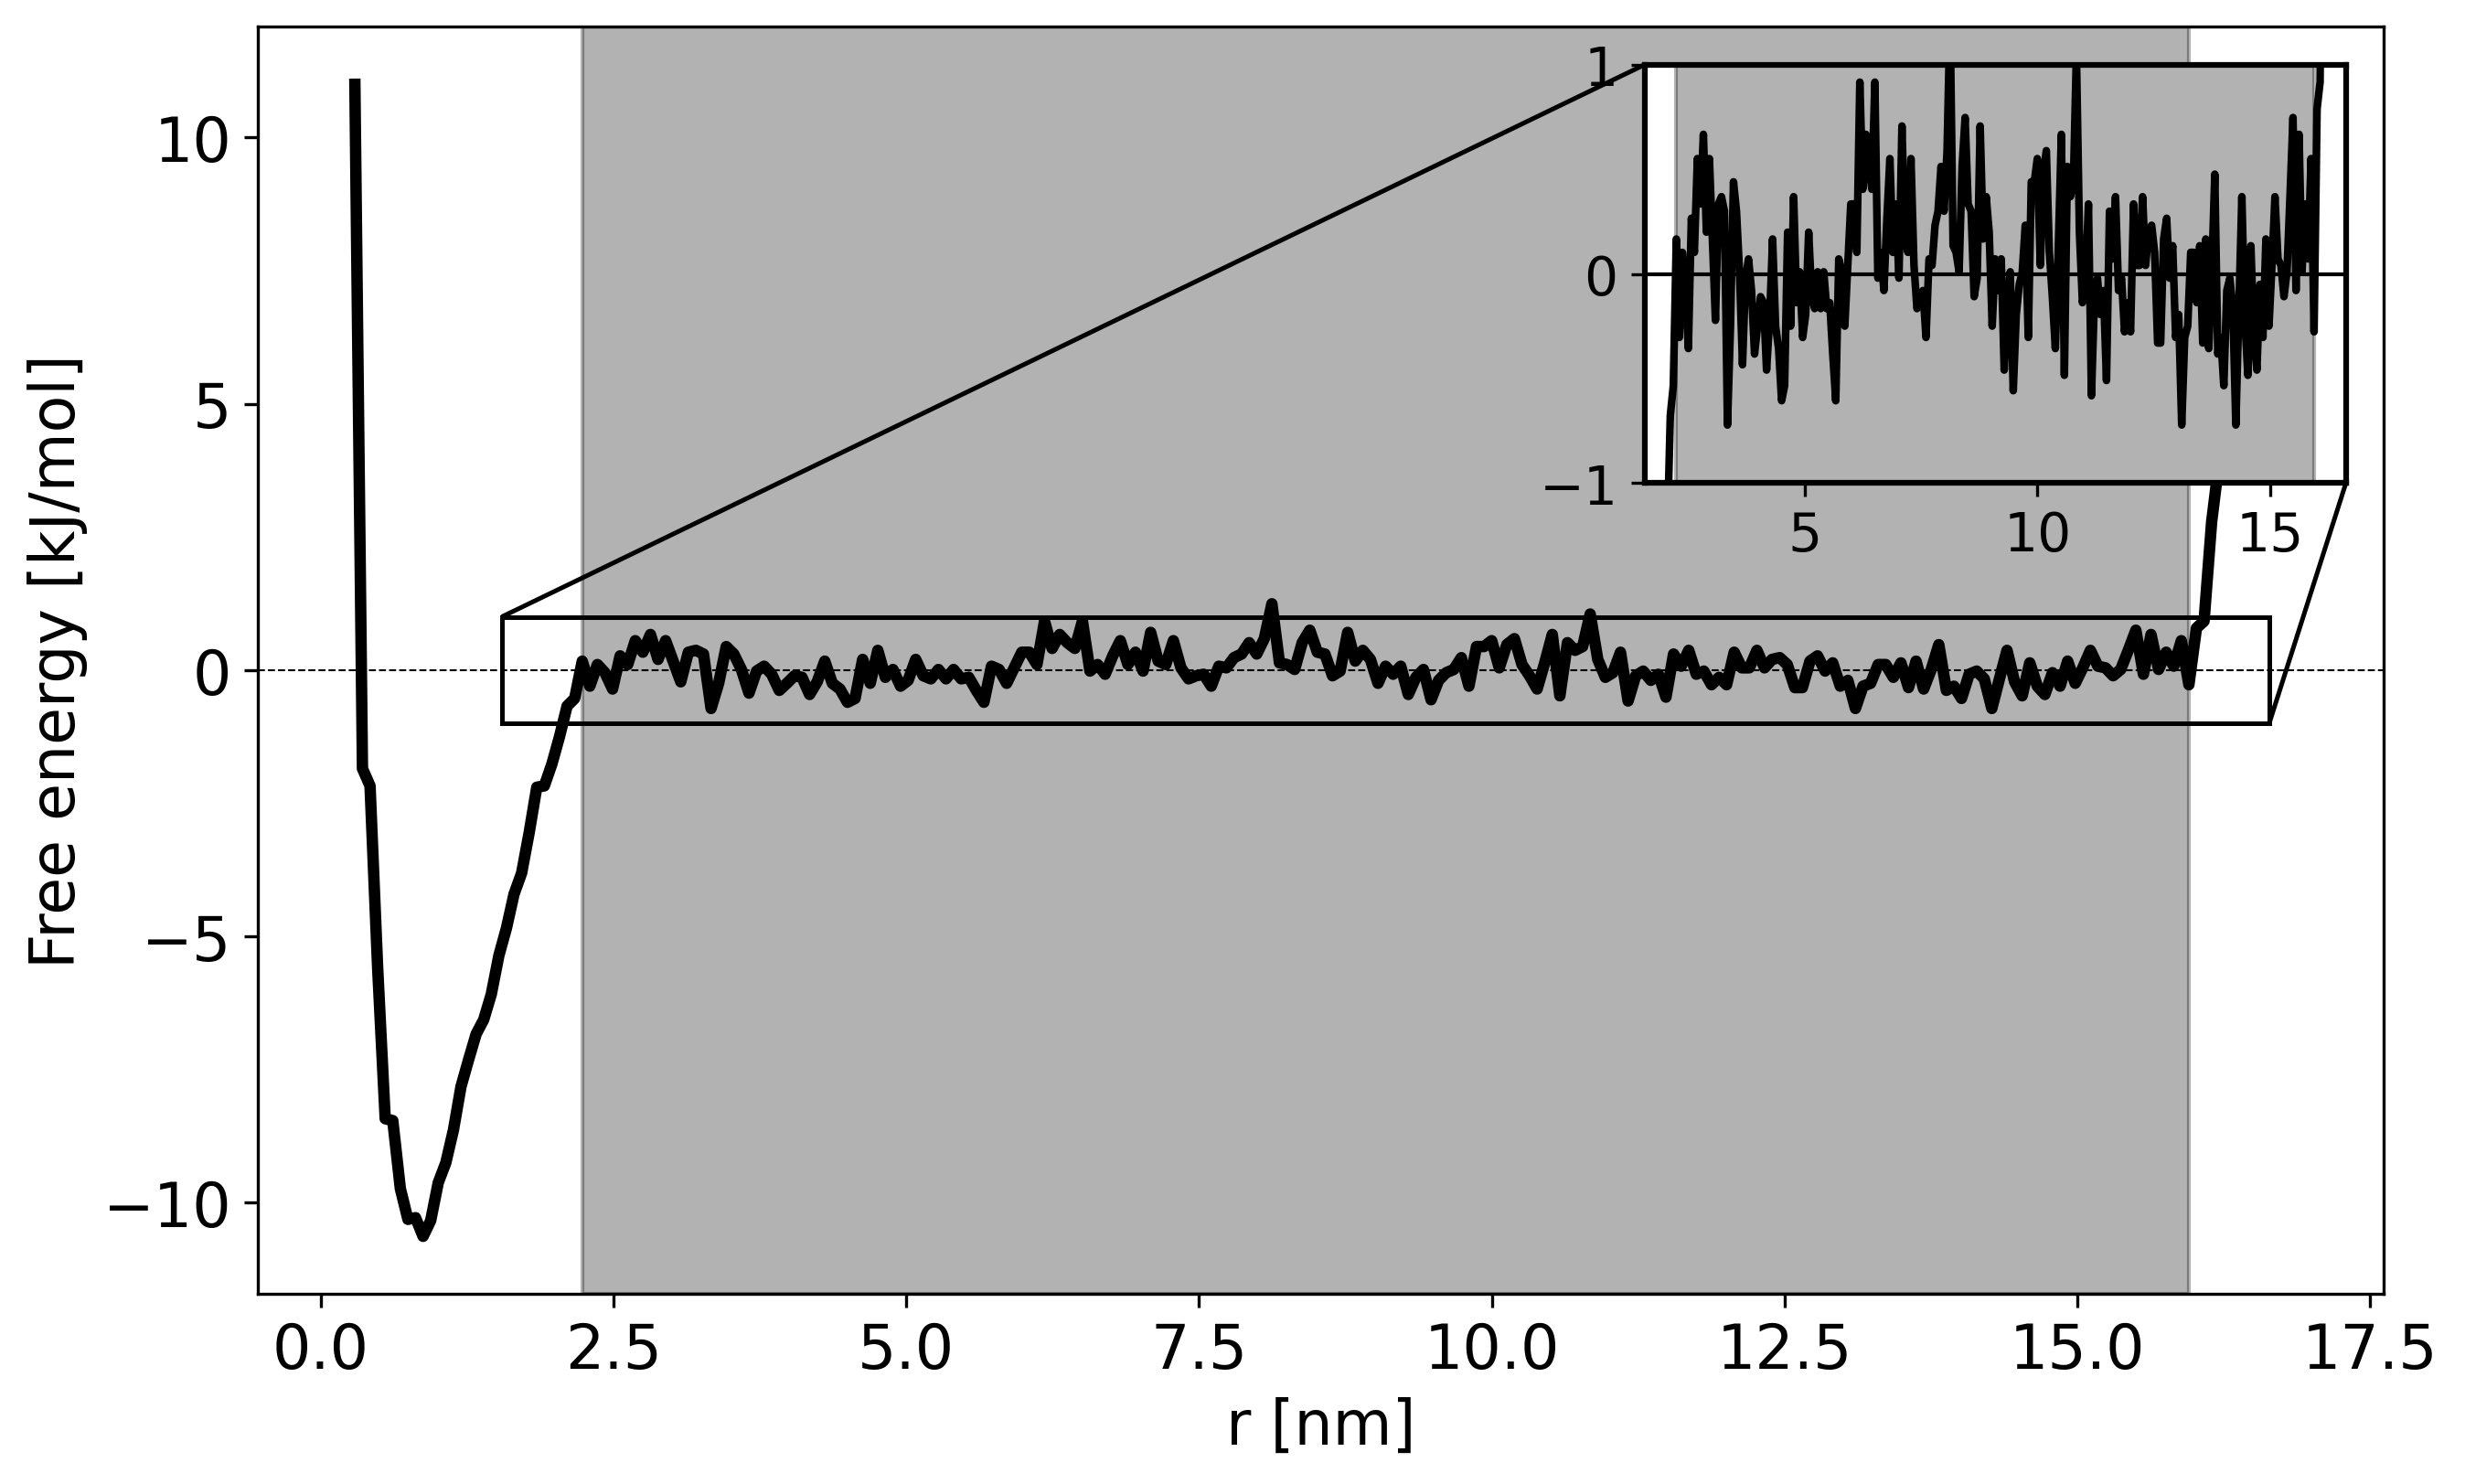

Processing system: Man9/TIP4PD


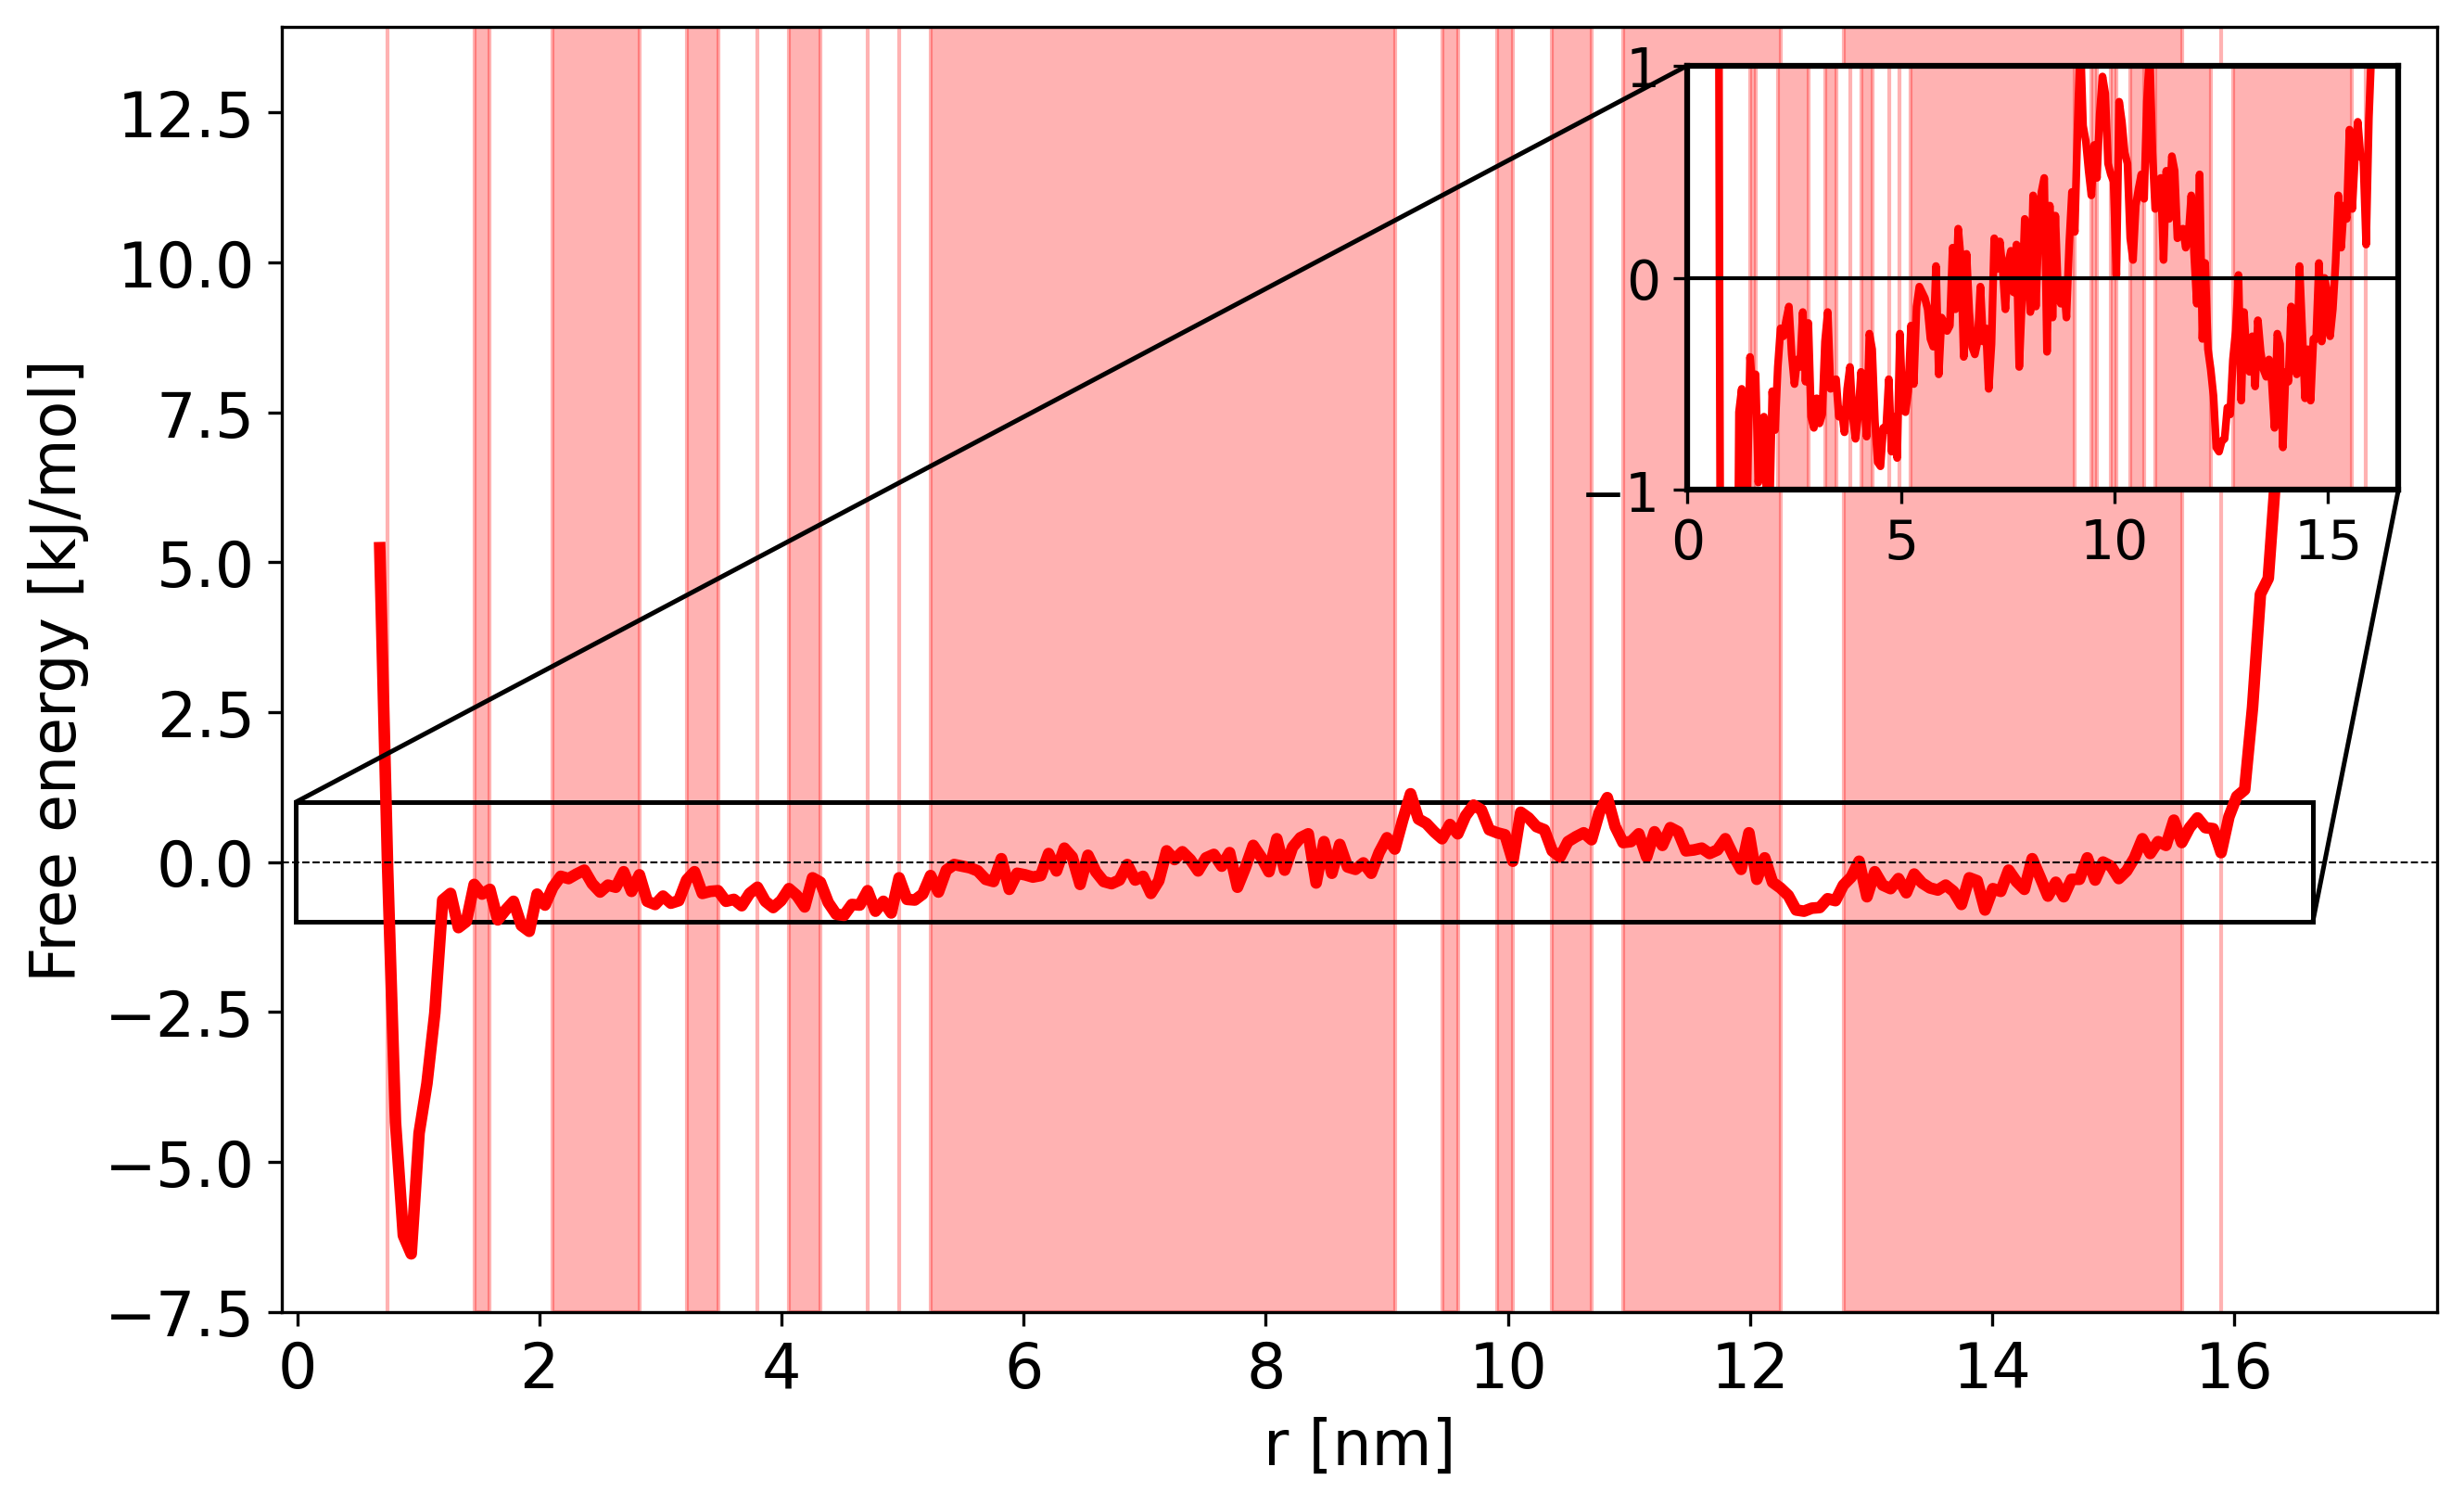

Processing system: Man9/TIP4PD--


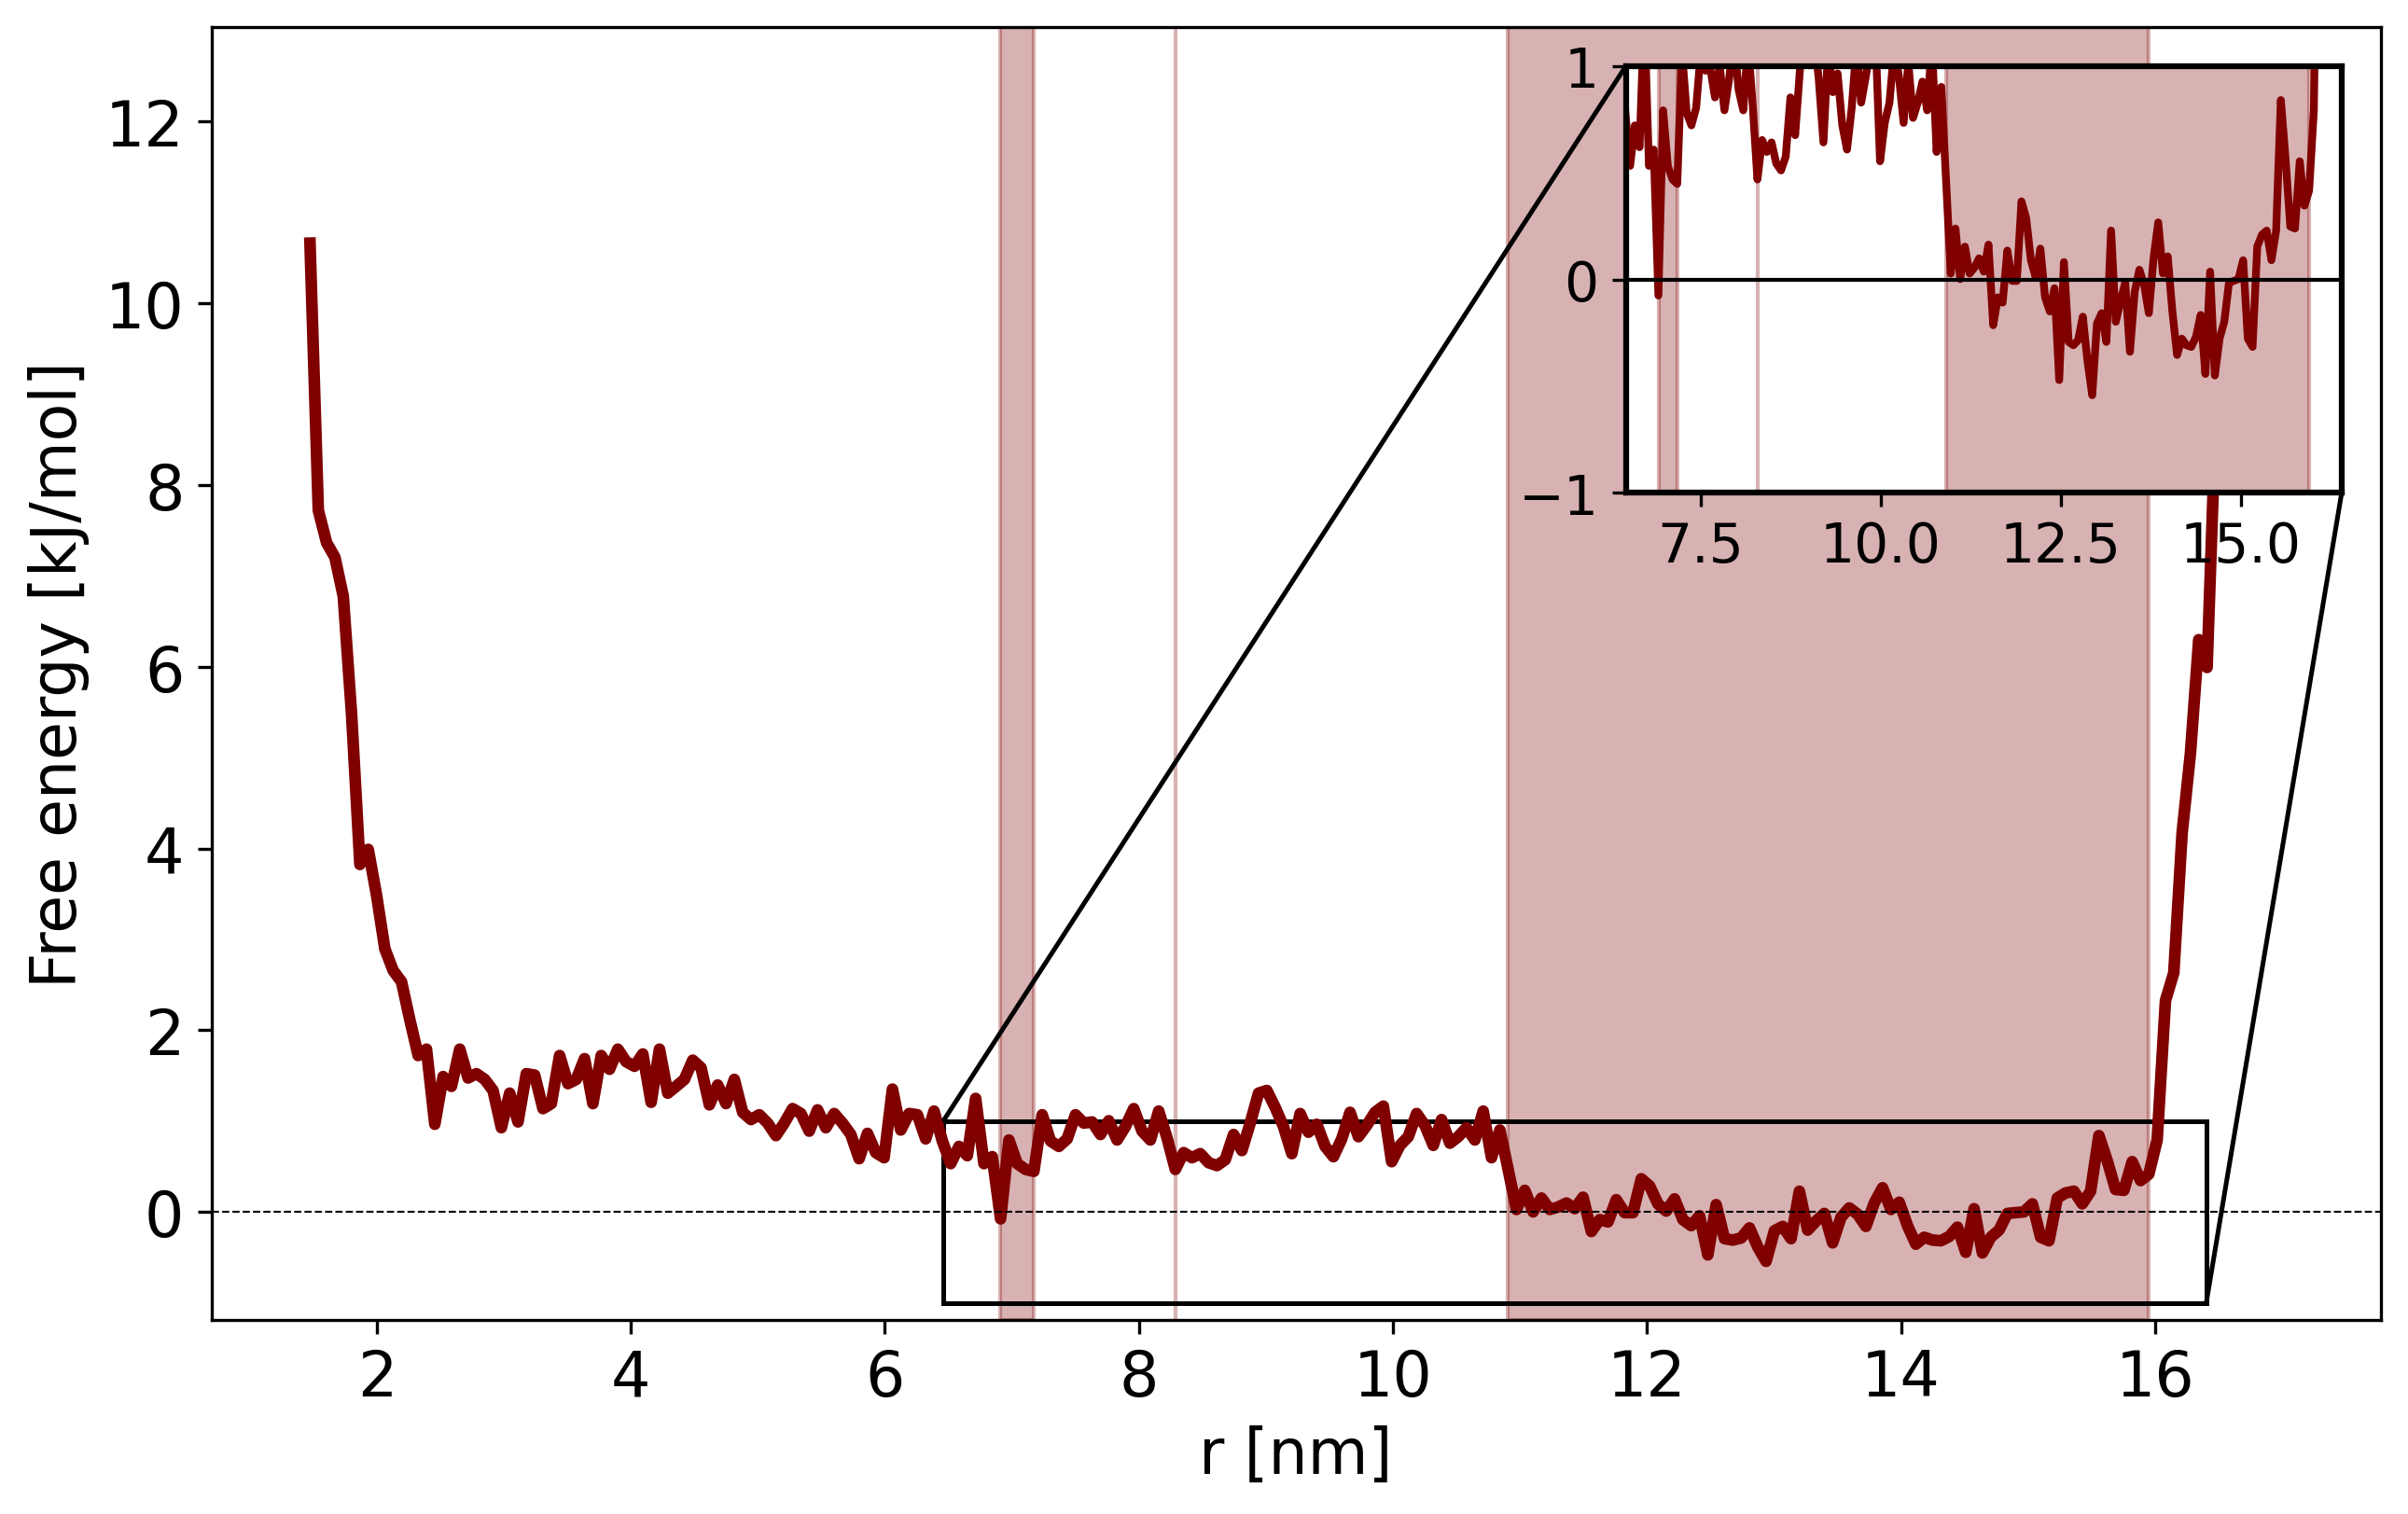

In [5]:
color = ['black', 'red', 'maroon']
merged_ranges_models = {}
for key, c in zip( keys["all"], color):
    print("Processing system: {}".format(key))  
    merged_ranges = b22.calc_plot_FEP(data, key, fit_range_lower = 14, fit_range_upper = 15.9, threshold = 0.5, max_gap = 0.2, color = c, fontsize = 16)
    merged_ranges_models[key] = merged_ranges

### 2. Test R1 ranges

Processing system: Man9/TIP3P


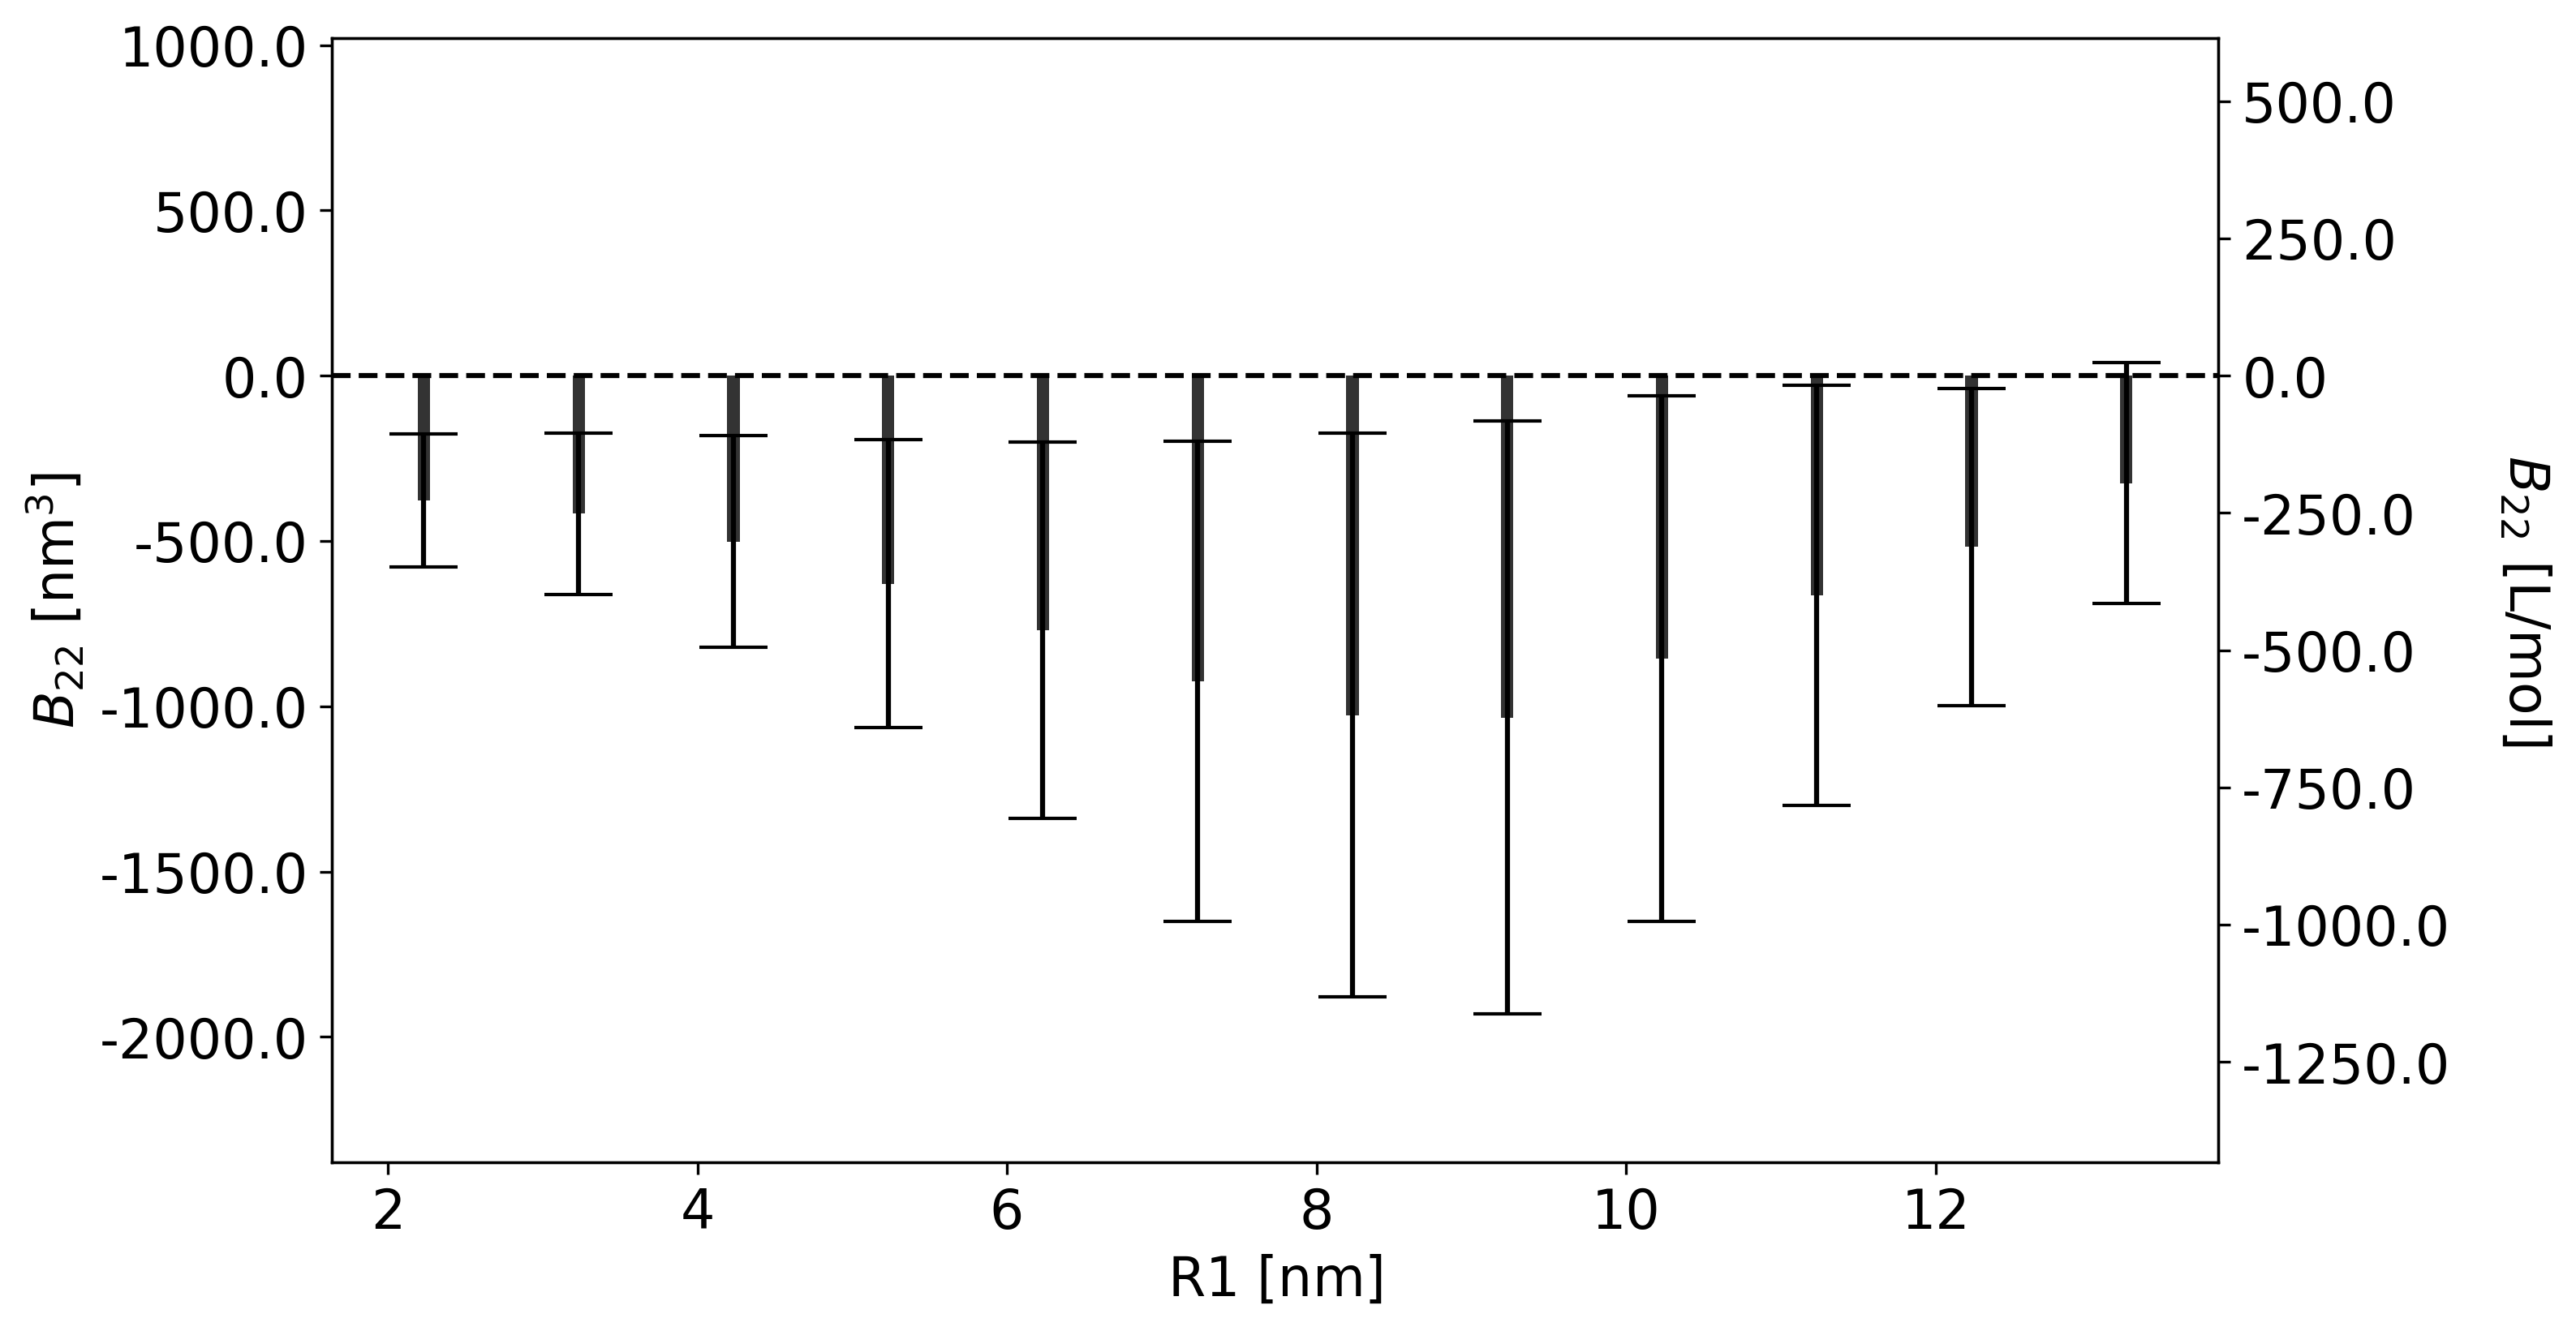

Processing system: Man9/TIP4PD


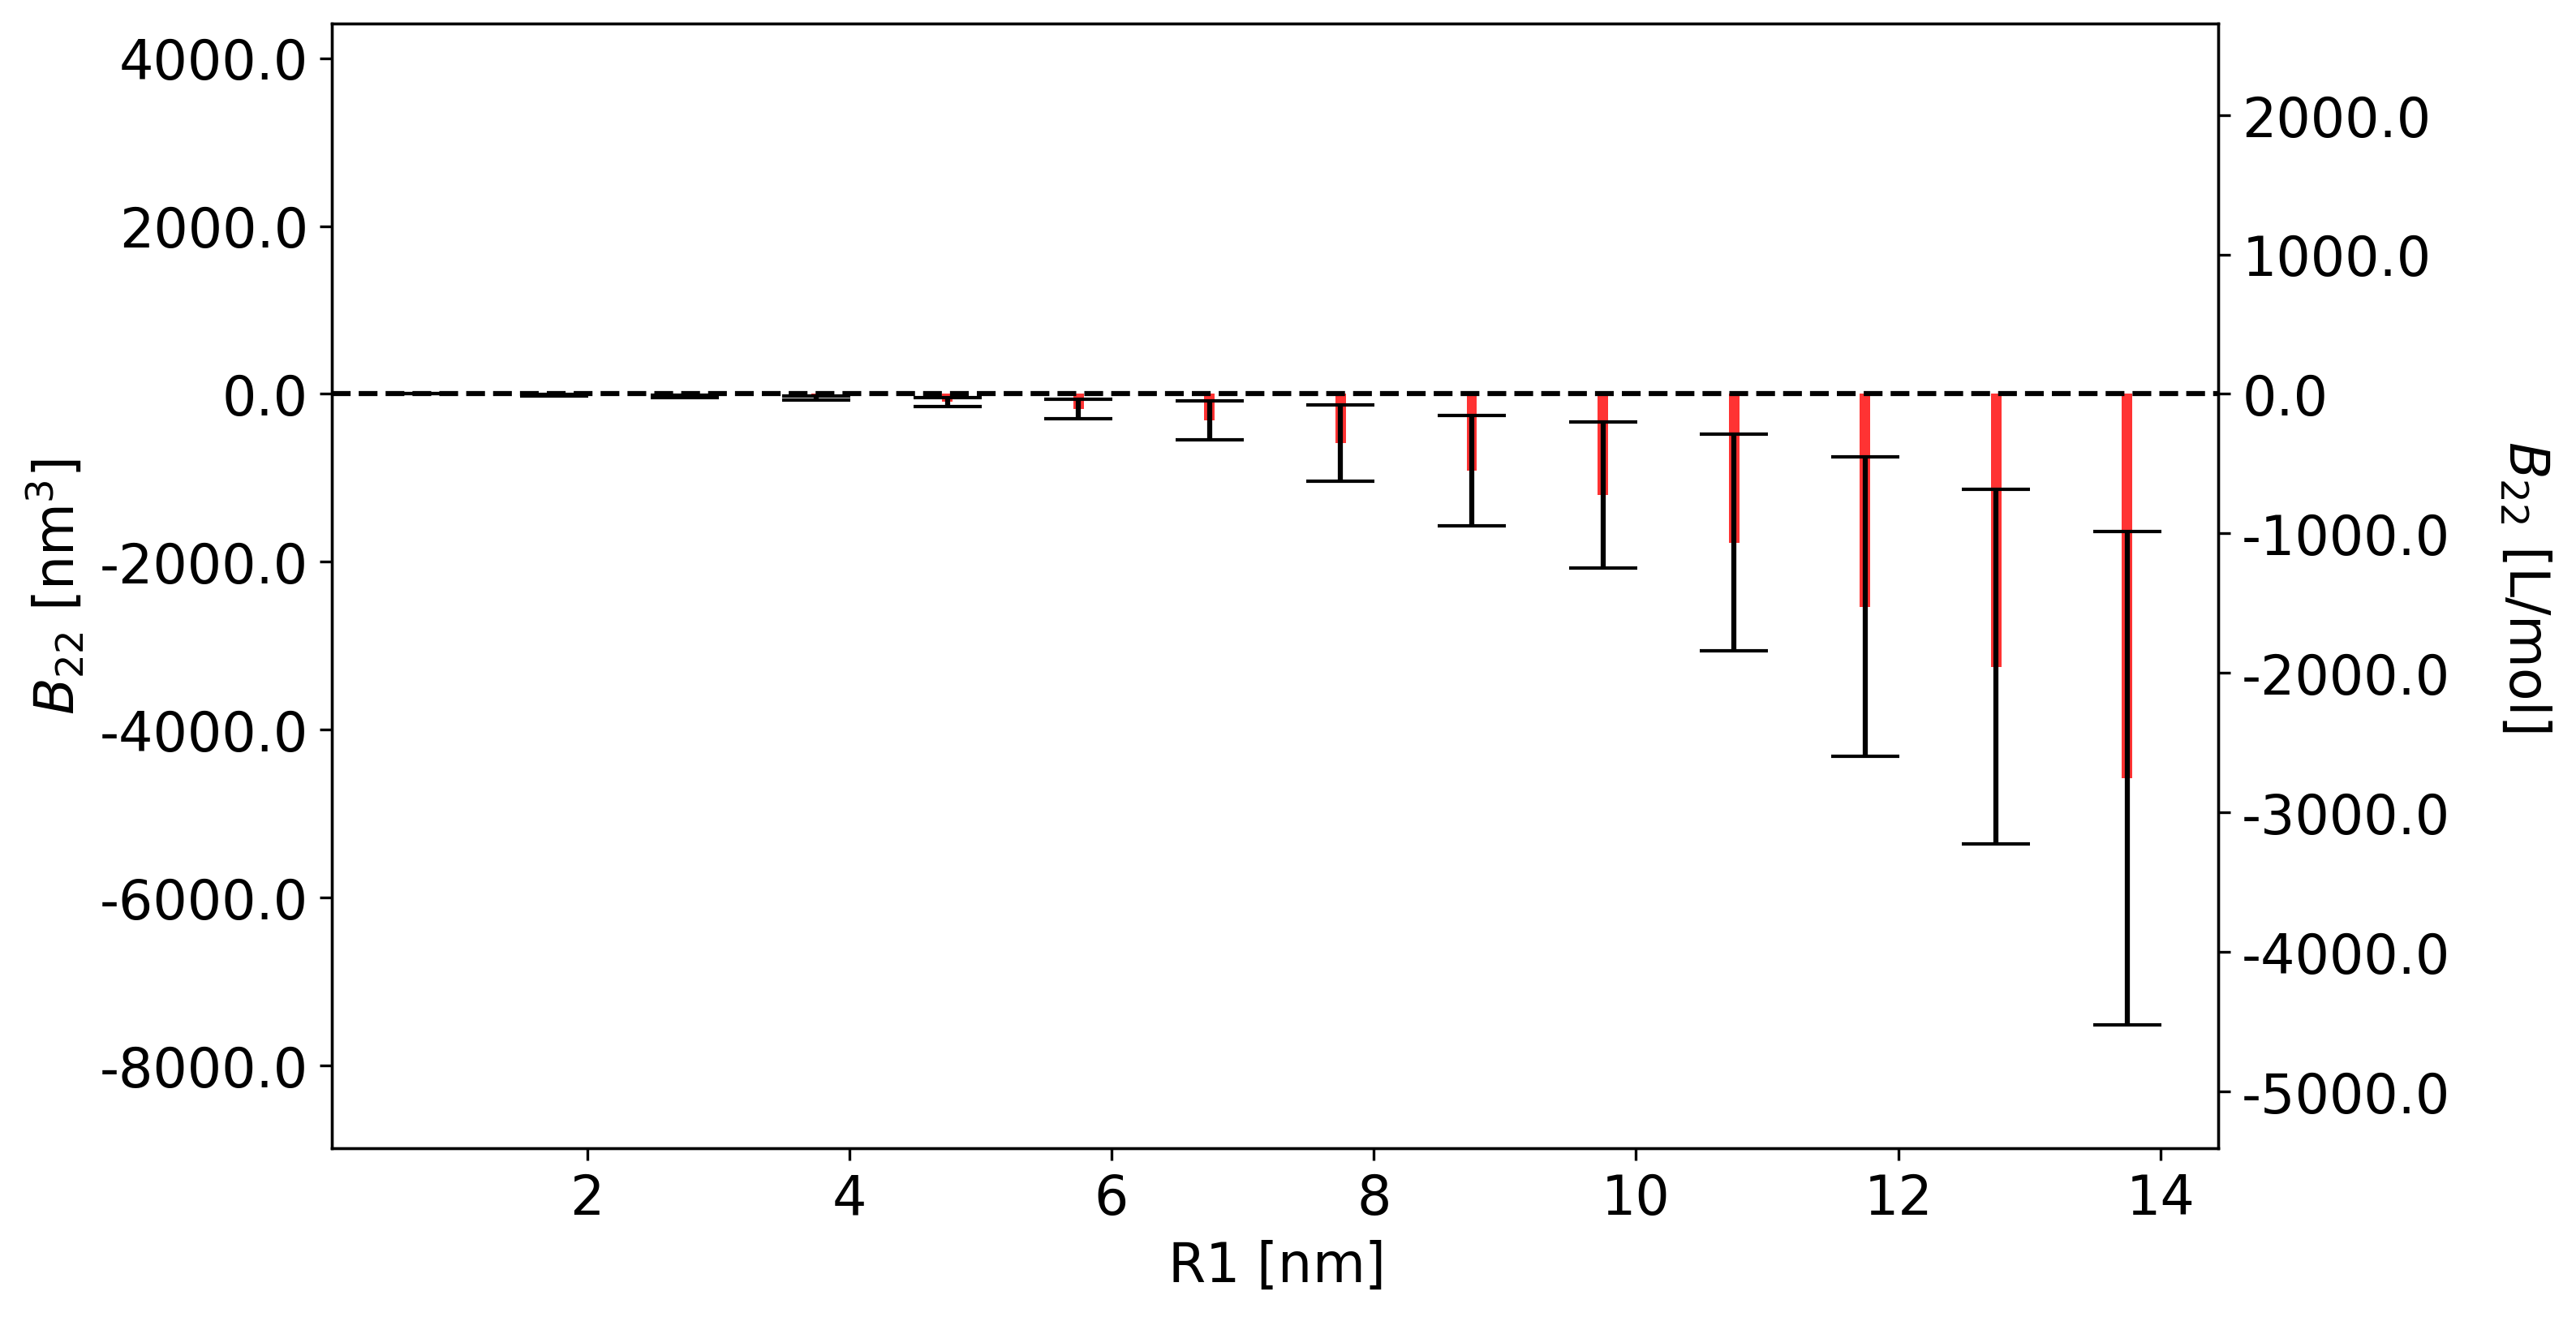

Processing system: Man9/TIP4PD--


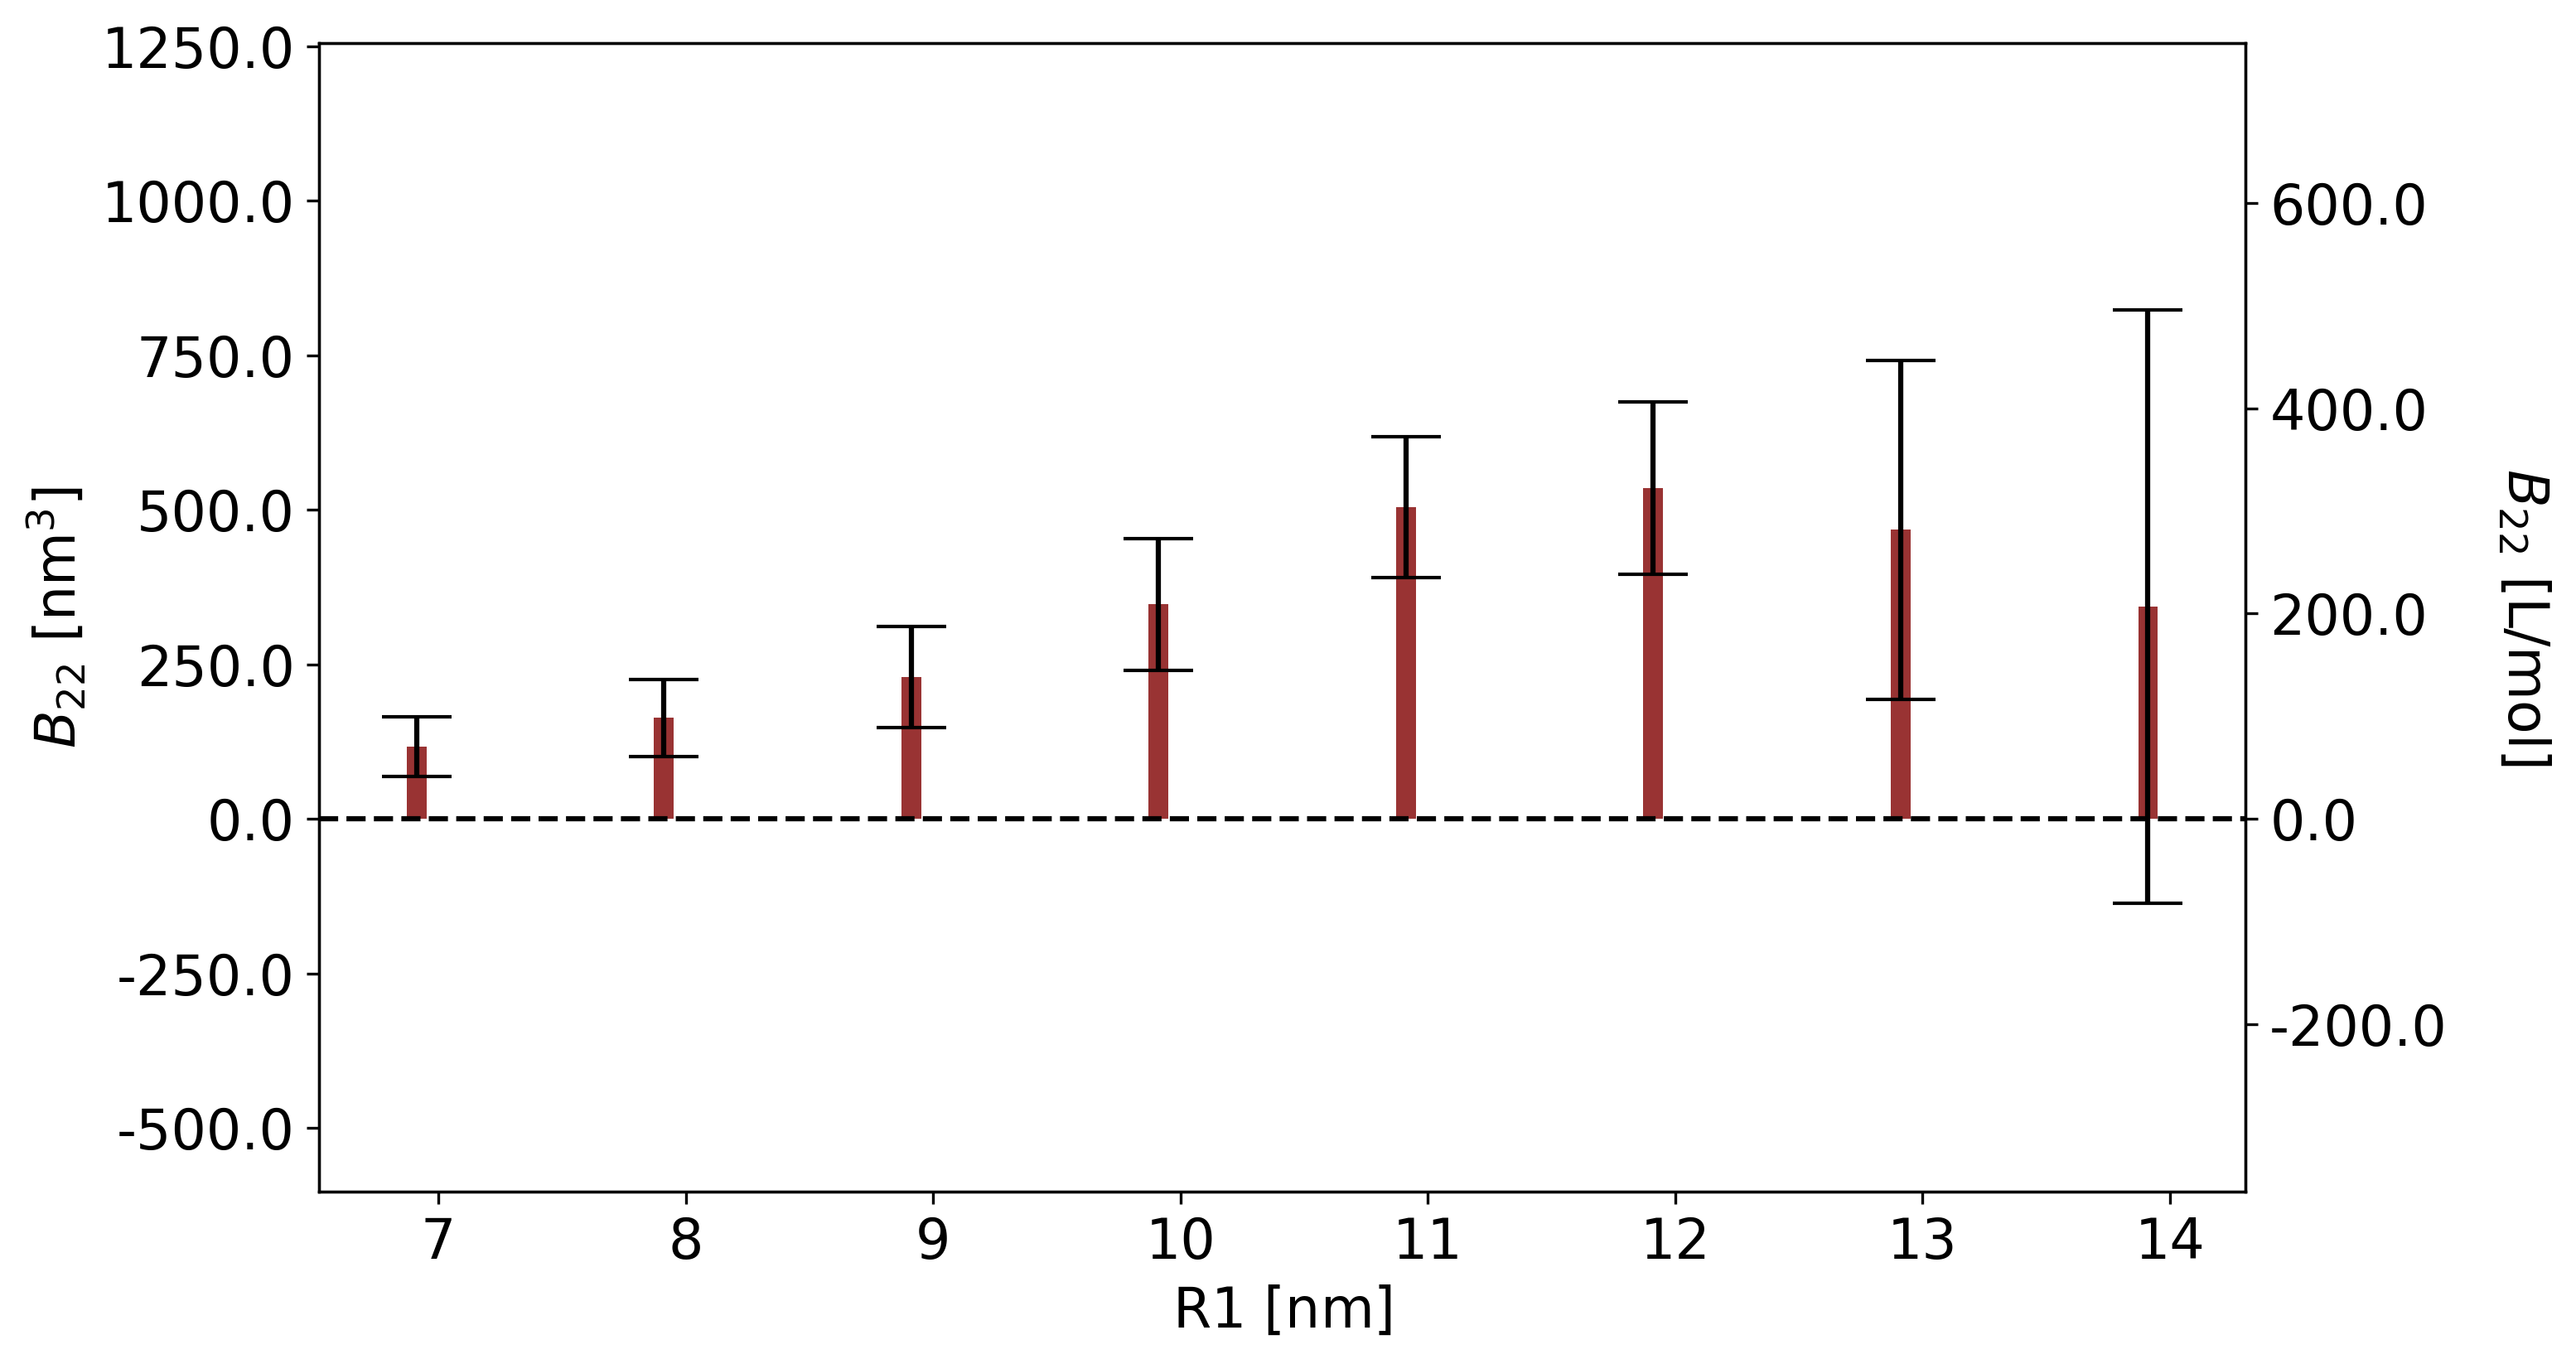

In [6]:
#modify R2 and R1_test_range accordingly
R2 = {}
color = ['black', 'red', 'maroon']
for key, c in zip(keys["all"], color):
    print("Processing system: {}".format(key))
    R2[key] = data['distance'][key][:,1].max() * 0.90
    R1_test_range = np.arange(merged_ranges_models[key][0][0], R2[key] -1, 1)
    b22.plot_B22_for_R1_range(data, R1_test_range, R2, key, n_blocks = 5, color = c, fontsize = 16, ylim_min = None, ylim_max = None)

### 3. Calculate B22 over R1 range

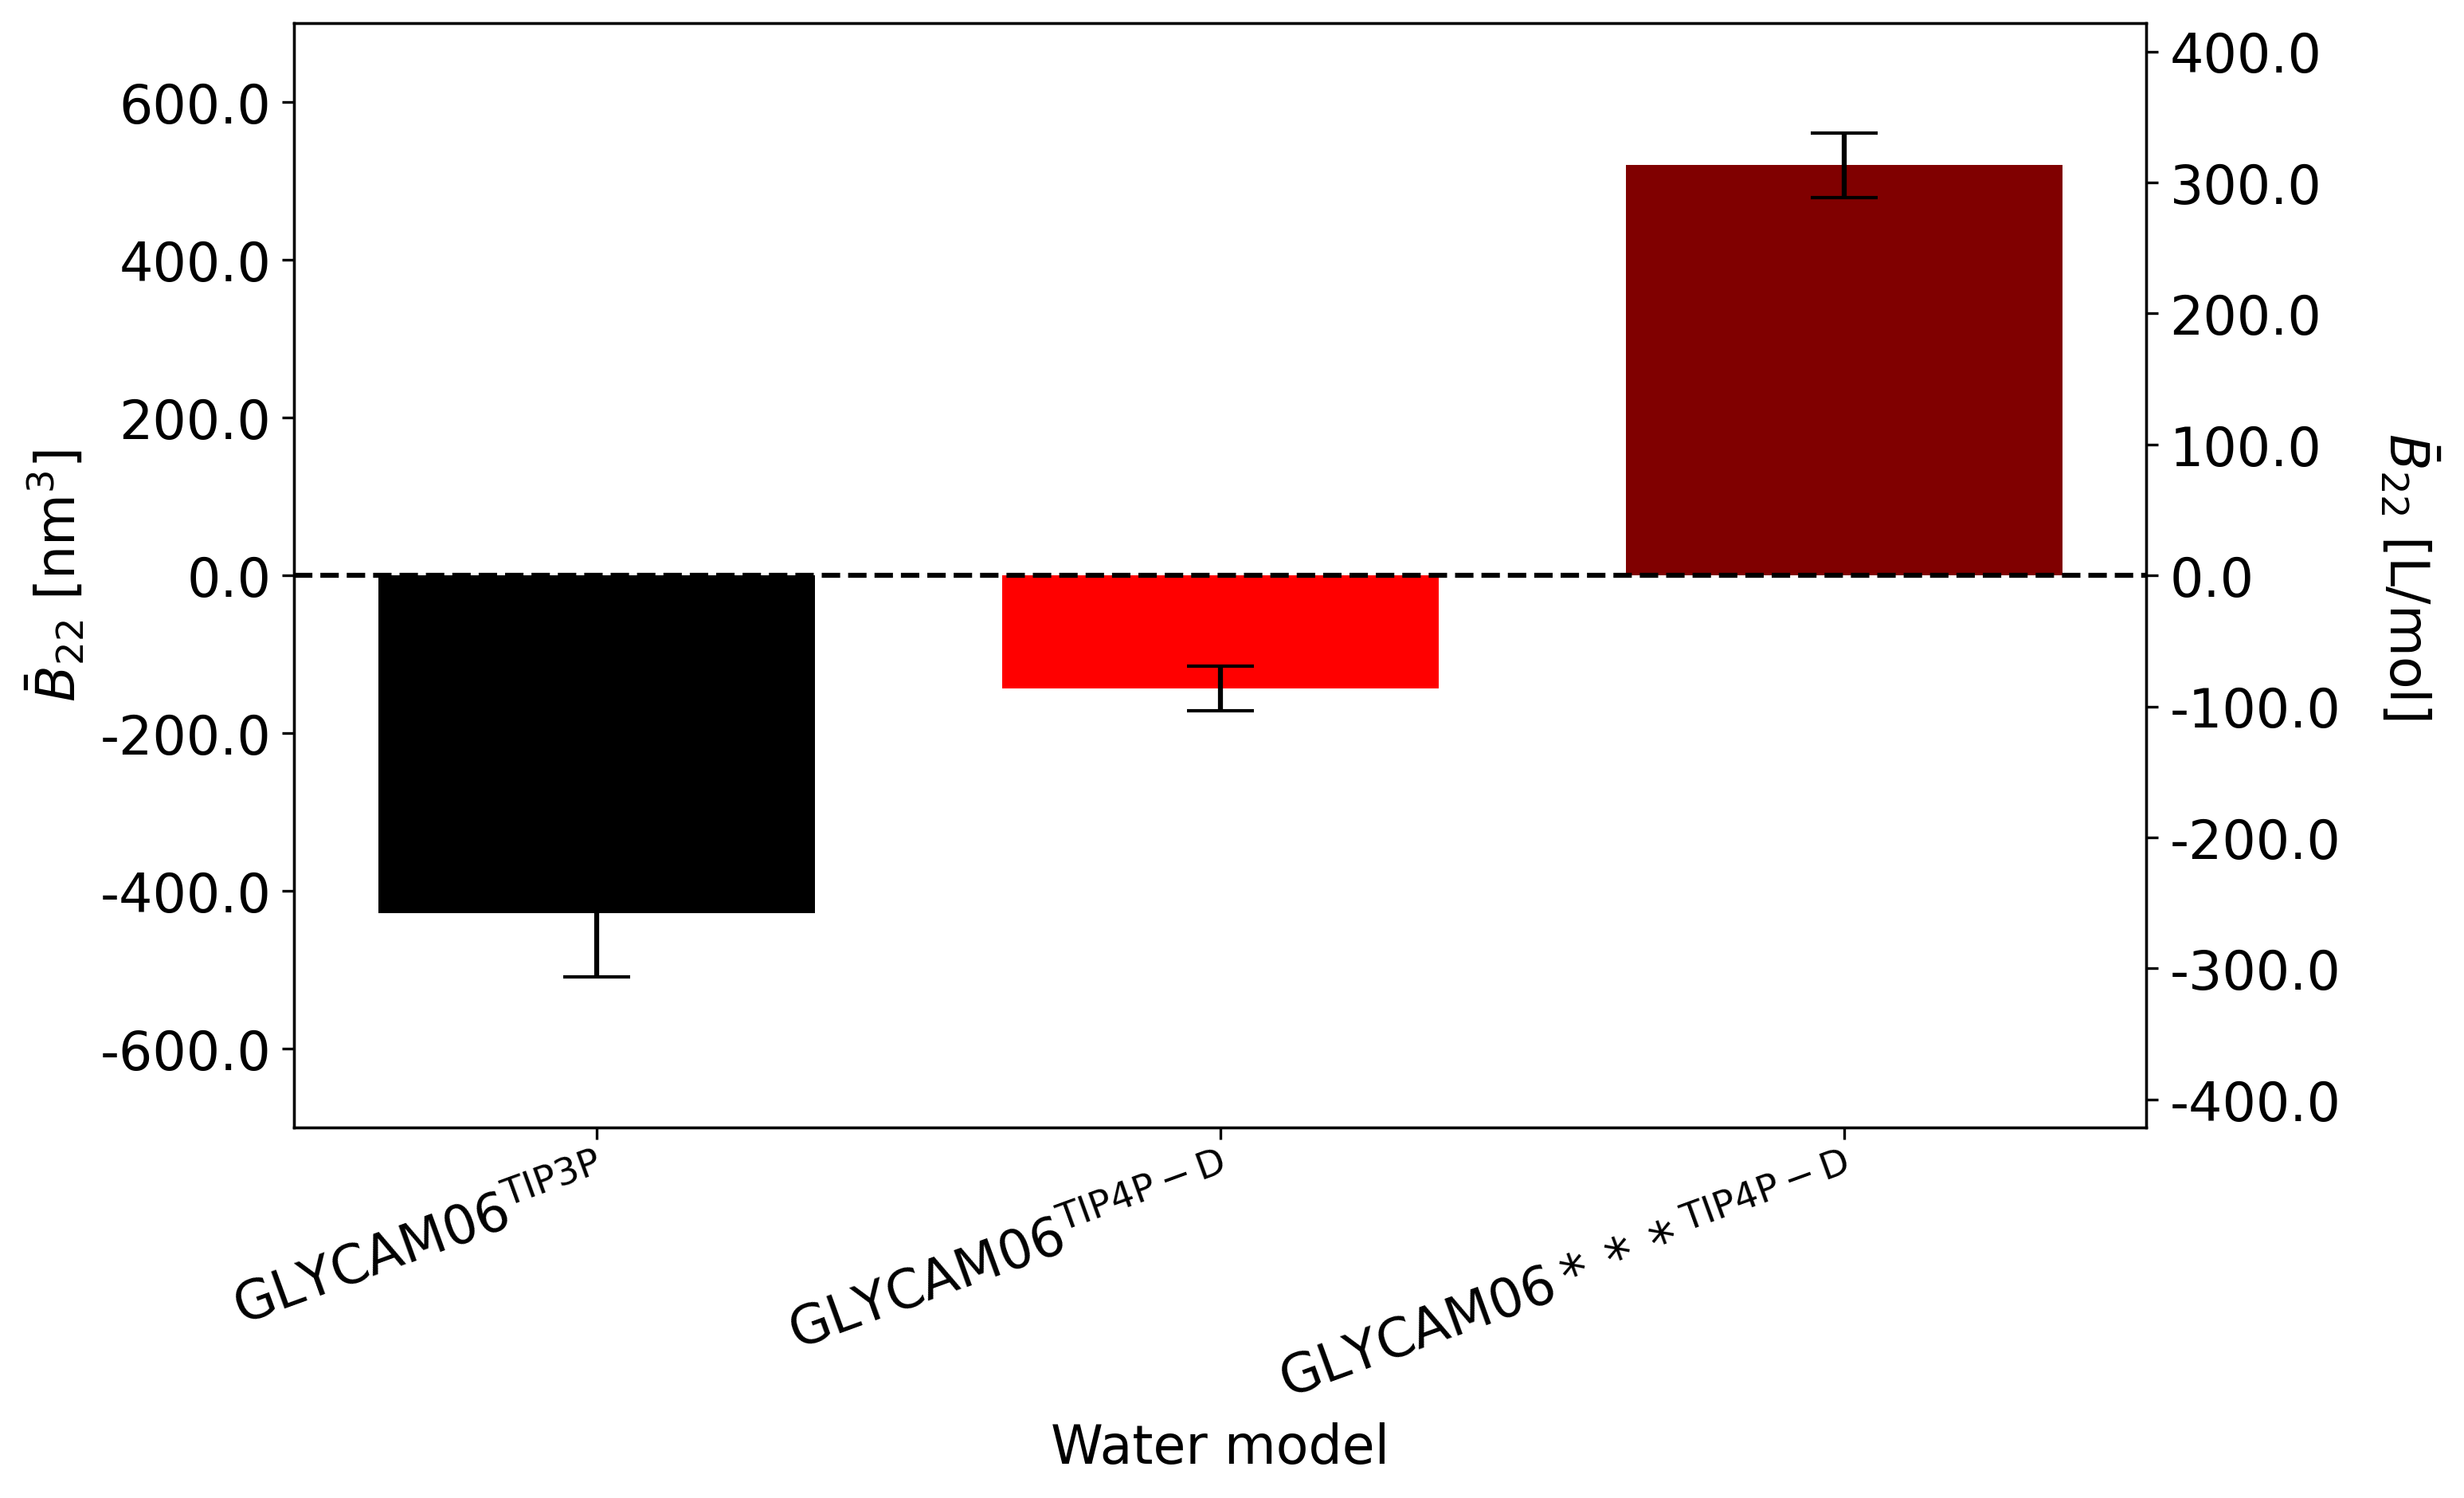

In [7]:
R1_ranges = {
    "Man9/TIP3P": np.arange(3, 4, 0.1),
    "Man9/TIP4PD": np.arange(5, 6, 0.1),
    "Man9/TIP4PD--": np.arange(11, 12, 0.1)
}

B22_means, B22_errs = b22.calculate_and_plot_B22(data, keys["all"], R1_ranges,
    colors=['black','red','maroon'],
    labels=[r"$\mathrm{GLYCAM06^{TIP3P}}$",
        r"$\mathrm{GLYCAM06^{TIP4P-D}}$",
        r"$\mathrm{GLYCAM06***^{TIP4P-D}}$"],
    ylim=(-700, 700)
)